In [1]:
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# načtení galIMF modulu z cesty
spec = importlib.util.spec_from_file_location(
    "gal",
    "/Users/karel/PycharmProjects/galIMF/galIMF_version_1.0.py"
)
gal = importlib.util.module_from_spec(spec)
spec.loader.exec_module(gal)


In [2]:
def generate_optimal_cluster(M_ecl):
    gal.function_sample_from_IMF(
        M_ecl,
        1,      # I_ecl
        0.08,   # m_low
        1.3,    # alpha1
        0.5,    # m_s1
        2.3,    # alpha2
        1.0,    # m_s2
        2.3,    # alpha3
        150     # m_max_star
    )

    masses = []
    for m, n in zip(gal.list_M_str_i, gal.list_n_str_i):
        masses.extend([float(m)] * int(n))

    return masses

In [3]:
try:
    test_masses = generate_optimal_cluster(50)
    print(f"Generated {len(test_masses)} stars.")
    print(f"Most massive star: {max(test_masses):.2f} M_sun")
    print(f"Total cluster mass: {sum(test_masses):.2f} M_sun")
except Exception as e:
    print(f"Error: Probably an incorrect file path or a missing file.\nDetail: {e}")

Generated 113 stars.
Most massive star: 4.75 M_sun
Total cluster mass: 49.97 M_sun


In [4]:
from scipy.integrate import quad

def custom_imf_unnormalized(m):
    if m < 0.08:
        return 0
    elif m < 0.5:
        return 2 * m**(-1.3)
    elif m < 1.0:
        return m**(-2.3)
    elif m <= 150:
        return m**(-2.3)
    else:
        return 0

def mass_weighted_imf(m):
    return m * custom_imf_unnormalized(m)

integrated_mass_val, _ = quad(mass_weighted_imf, 0.08, 150)

def get_theoretical_imf(m_array, M_cl):
    norm_factor = M_cl / integrated_mass_val

    res = []
    for m in m_array:
        res.append(custom_imf_unnormalized(m) * norm_factor)
    return np.array(res)

In [5]:
M_cl_target = 50

masses = np.array(generate_optimal_cluster(M_cl_target))

m_theory = np.logspace(np.log10(0.08), np.log10(150), 500)
y_theory = get_theoretical_imf(m_theory, M_cl_target)
y_theory_corrected = y_theory

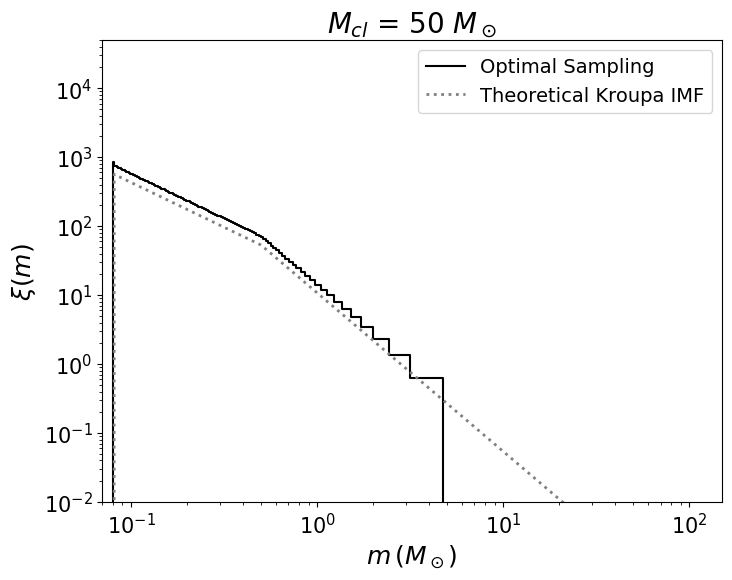

In [6]:
m_sorted = np.sort(masses)

edges = np.concatenate([[0.08], m_sorted, [150]])

dm = np.diff(edges)
y_vals = 1.0 / dm

m_plot = edges
y_plot = np.insert(y_vals, 0, 0)
plt.figure(figsize=(8, 6))

plt.step(m_plot, y_plot, where='pre', color='black', lw=1.5, label='Optimal Sampling')

plt.plot(m_theory, y_theory_corrected, color='gray', ls=':', lw=2, label='Theoretical Kroupa IMF')

plt.xscale('log')
plt.yscale('log')

plt.xlim(0.07, 150)
plt.ylim(1e-2, 5e4)

plt.xlabel(r'$m\,(M_\odot)$', fontsize=18)
plt.ylabel(r'$\xi(m)$', fontsize=18)
plt.title(fr'$M_{{cl}}$ = {M_cl_target} $M_\odot$', fontsize=20)


plt.tick_params(axis='both', which='major', labelsize=15)
plt.tick_params(axis='both', which='minor', labelsize=12)
plt.legend(fontsize=14)

plt.show()

In [7]:
random_df = pd.read_csv("/My_project/random_sampling_results.csv")
opt_df = pd.read_csv("/My_project/optimal_sampling_clusters_more.csv")

M_list = random_df["realized_mass"]
mmax_list = random_df["m_max"]

M_list_opt = opt_df["realized_mass"]
mmax_list_opt = opt_df["m_max"]

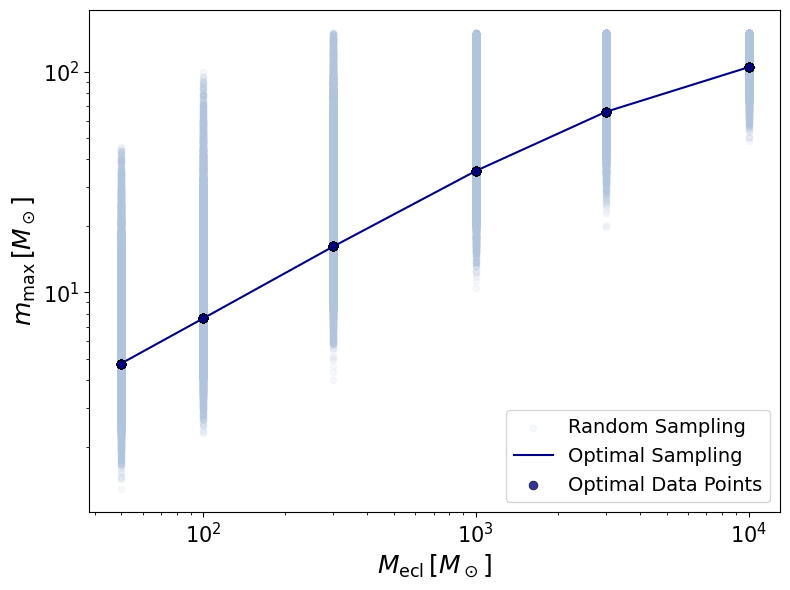

In [8]:
plt.figure(figsize=(8,6))

plt.scatter(M_list, mmax_list,
            alpha=0.1, color="lightsteelblue", s=20, label="Random Sampling")

sort_idx = np.argsort(M_list_opt)
M_opt_sorted = np.array(M_list_opt)[sort_idx]
mmax_opt_sorted = np.array(mmax_list_opt)[sort_idx]

plt.plot(M_opt_sorted, mmax_opt_sorted,
         color="navy", lw=1.5, label="Optimal Sampling", zorder=10)

plt.scatter(M_list_opt, mmax_list_opt,
            color="navy", s=40, edgecolor="black", linewidth=0.5,
            alpha=0.8, label="Optimal Data Points", zorder=11)
plt.xscale('log')
plt.yscale('log')

plt.xlabel(r"$M_{\mathrm{ecl}}\,[M_\odot]$", fontsize=18)
plt.ylabel(r"$m_{\max}\,[M_\odot]$", fontsize=18)
plt.tick_params(axis='both', which='major', labelsize=15)

plt.legend(fontsize=14)

plt.tight_layout()
plt.show()

In [9]:
from My_project.Thesis.Simulated_clusters_ran import generate_random_cluster

In [10]:
m_cl_test_range = np.linspace(10, 500, 982)
target_m = 20.0
found_threshold = None

for M_cl in m_cl_test_range:
    stars = generate_optimal_cluster(M_cl)

    if max(stars) >= target_m:
        found_threshold = M_cl
        break

if found_threshold:
    print(f"A star with mass {target_m} M_sun appears in optimal sampling")
    print(f"for the first time at a total cluster mass of: {found_threshold} M_sun")
else:
    print("No threshold was found in the given range.")

A star with mass 20.0 M_sun appears in optimal sampling
for the first time at a total cluster mass of: 412.58919469928645 M_sun


In [11]:
try:
    test_masses = generate_optimal_cluster(412.58919469928645)
    print(f"Generated {len(test_masses)} stars.")
    print(f"Most massive star: {max(test_masses):.2f} M_sun")
    print(f"Total cluster mass: {sum(test_masses):.2f} M_sun")
except Exception as e:
    print(f"Error: Probably an incorrect file path or a missing file.\nDetail: {e}")

Generated 790 stars.
Most massive star: 20.00 M_sun
Total cluster mass: 412.59 M_sun


In [12]:
M_crit = 412.58919469928645
target_m = 20.0
n_simulations = 10000

count_massive = 0

print(f"Running {n_simulations} random sampling simulations for M_cl = {M_crit} M_sun...")

for _ in range(n_simulations):
    stars = generate_random_cluster(M_crit)

    if len(stars) > 0 and max(stars) >= target_m:
        count_massive += 1

probability = (count_massive / n_simulations) * 100

print("-" * 40)
print(f"Result for random sampling at M_cl = {M_crit}:")
print(f"A star with mass >= {target_m} M_sun appeared in {count_massive} cases.")
print(f"The occurrence probability is: {probability:.2f} %")

Running 10000 random sampling simulations for M_cl = 412.58919469928645 M_sun...
----------------------------------------
Result for random sampling at M_cl = 412.58919469928645:
A star with mass >= 20.0 M_sun appeared in 7369 cases.
The occurrence probability is: 73.69 %


Počítám pravděpodobnosti (RS může chvíli trvat)...


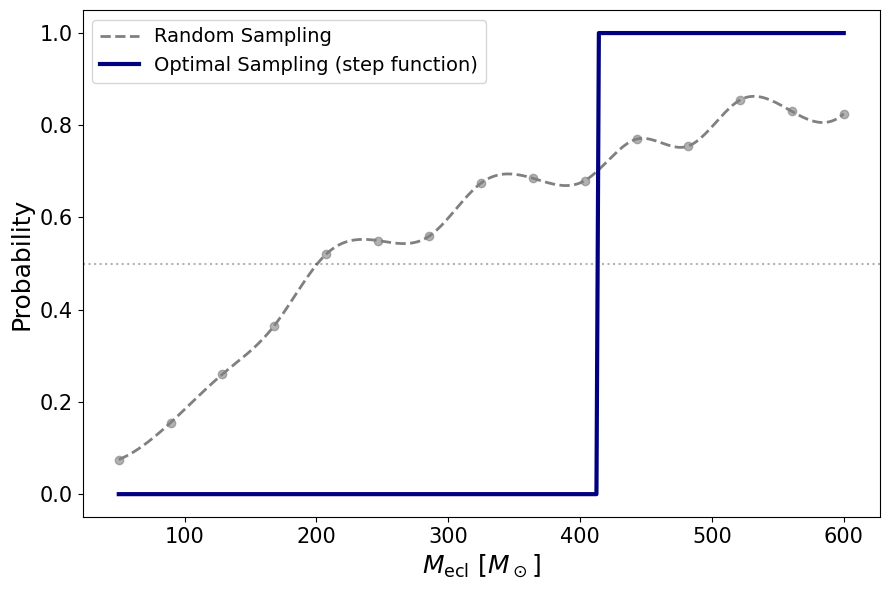

In [164]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline

target_m = 20.0
m_cl_range_rs = np.linspace(50, 600, 15)
m_cl_range_os = np.linspace(50, 600, 300)
n_sim_rs = 200

probs_rs = []
probs_os = []

for M_cl in m_cl_range_rs:
    hits = 0
    for _ in range(n_sim_rs):
        stars = generate_random_cluster(M_cl)
        if len(stars) > 0 and max(stars) >= target_m:
            hits += 1
    probs_rs.append(hits / n_sim_rs)

for M_cl in m_cl_range_os:
    stars = generate_optimal_cluster(M_cl)
    if len(stars) > 0 and max(stars) >= target_m:
        probs_os.append(1.0)
    else:
        probs_os.append(0.0)

X_rs_smooth = np.linspace(m_cl_range_rs.min(), m_cl_range_rs.max(), 300)
spl = make_interp_spline(m_cl_range_rs, probs_rs, k=3)
y_rs_smooth = spl(X_rs_smooth)
y_rs_smooth = np.clip(y_rs_smooth, 0, 1)

plt.figure(figsize=(9, 6))

plt.scatter(m_cl_range_rs, probs_rs, color='gray', alpha=0.6)
plt.plot(X_rs_smooth, y_rs_smooth, color='gray', linestyle='--', lw=2, label='Random Sampling')

plt.plot(m_cl_range_os, probs_os, color='navy', lw=3, label='Optimal Sampling (step function)', zorder=5)

plt.axhline(0.5, color='black', ls=':', alpha=0.3) # 50% hranice
plt.xlabel(r'$M_{\mathrm{ecl}} \ [M_\odot]$', fontsize=18)
plt.ylabel(f'Probability', fontsize=18)
plt.tick_params(axis='both', which='major', labelsize=15)
plt.legend(fontsize=14, loc='upper left')

plt.tight_layout()
plt.show()

Generating data...


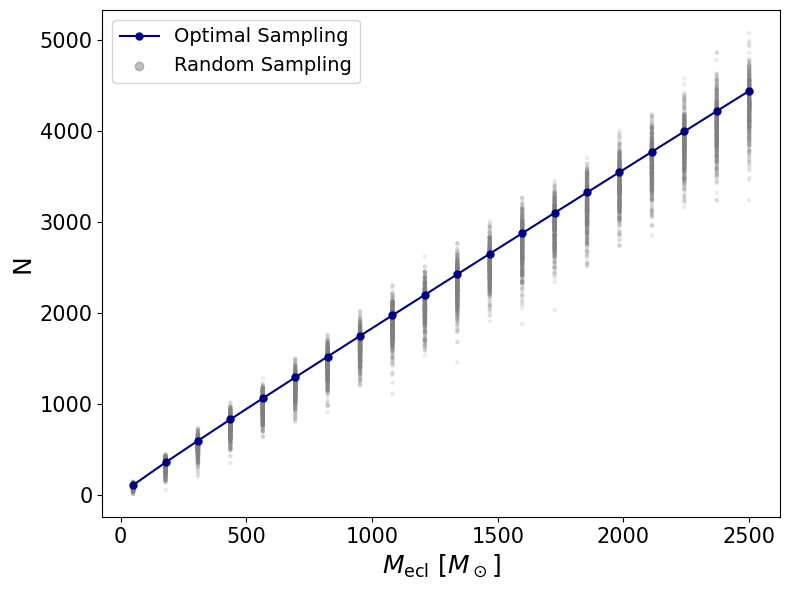

In [43]:
import matplotlib.pyplot as plt
import numpy as np

m_cl_samples = np.linspace(50, 2500, 20)
n_sim_per_point = 500

plt.figure(figsize=(8, 6))

os_m_values = []
os_n_values = []

print("Generating data...")

for M in m_cl_samples:
    n_rs = [len(generate_random_cluster(M)) for _ in range(n_sim_per_point)]
    plt.scatter([M] * n_sim_per_point, n_rs, color='gray', alpha=0.15, s=10, edgecolors='none')

    n_os = len(generate_optimal_cluster(M))
    os_m_values.append(M)
    os_n_values.append(n_os)

plt.plot(os_m_values, os_n_values, color='navy', marker='o', markersize=5,
         linewidth=1.5, label='Optimal Sampling', zorder=5)

plt.scatter([], [], color='gray', alpha=0.5, label='Random Sampling')

plt.xlabel(r'$M_{\mathrm{ecl}} \ [M_\odot]$', fontsize=18)
plt.ylabel('N', fontsize=18)
plt.tick_params(axis='both', which='major', labelsize=15)
plt.legend(loc='upper left', frameon=True, fontsize=14)

plt.tight_layout()
plt.show()

Generating relative dispersion data...


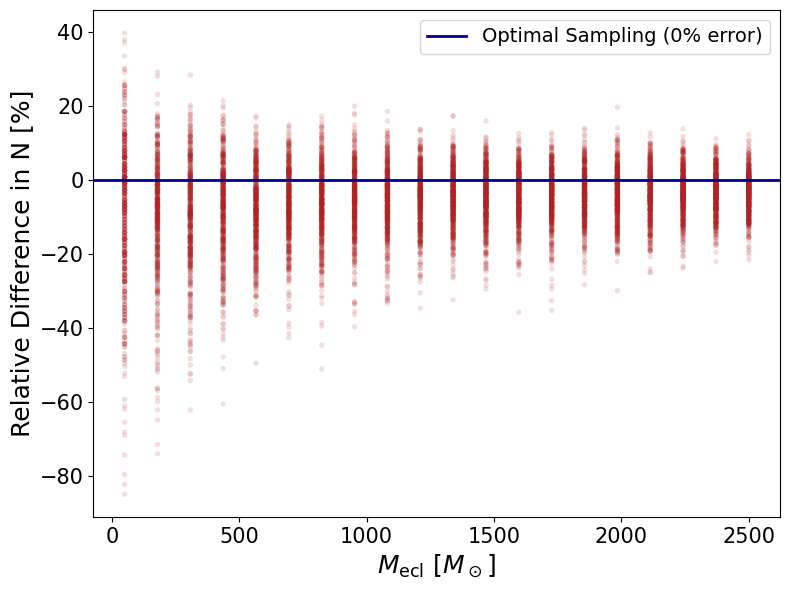

In [44]:
import matplotlib.pyplot as plt
import numpy as np

m_cl_samples = np.linspace(50, 2500, 20)
n_sim_per_point = 500

plt.figure(figsize=(8, 6))


for M in m_cl_samples:
    n_os = len(generate_optimal_cluster(M))

    n_rs_samples = [len(generate_random_cluster(M)) for _ in range(n_sim_per_point)]
    rel_diffs = [(n_rs - n_os) / n_os * 100 for n_rs in n_rs_samples]

    plt.scatter([M] * n_sim_per_point, rel_diffs, color='firebrick', alpha=0.15, s=15, edgecolors='none')

plt.axhline(0, color='navy', linestyle='-', linewidth=2, label='Optimal Sampling (0% error)')

plt.xlabel(r'$M_{\mathrm{ecl}} \ [M_\odot]$', fontsize=18)
plt.ylabel('Relative Difference in N [%]', fontsize=18)

plt.tick_params(axis='both', which='major', labelsize=15)
plt.legend(loc='upper right', frameon=True, fontsize=14)

plt.tight_layout()
plt.show()

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random_df = pd.read_csv("../data/random_sampling_results.csv")
optimal_df = pd.read_csv("../data/optimal_sampling_clusters.csv")

# Use a common name for the cluster mass
random_df = random_df.rename(columns={"target_mass": "M_cl"})
optimal_df = optimal_df.rename(columns={"target_mass": "M_cl"})

# Bin-fraction columns in the random-sampling file
bin_cols = [f"bin_{i}_fraction" for i in range(1, 11)]

# Rename optimal-sampling bin-fraction columns to match random_df
optimal_df = optimal_df.rename(columns={
    f"bin_{i}_number_fraction": f"bin_{i}_fraction"
    for i in range(1, 11)
})

rows = []

for M_cl, group in random_df.groupby("M_cl"):

    opt_row = optimal_df[optimal_df["M_cl"] == M_cl]

    if opt_row.empty:
        continue

    # Mean random realization in bin-fraction space
    random_mean = group[bin_cols].mean().values

    # L1 distances of random realizations from the random mean
    random_distances = np.sum(
        np.abs(group[bin_cols].values - random_mean),
        axis=1
    )

    # L1 distance of optimal sampling from the random mean
    opt_values = opt_row[bin_cols].iloc[0].values
    d_opt = np.sum(np.abs(opt_values - random_mean))

    rows.append({
        "M_cl": M_cl,
        "random_p10": np.percentile(random_distances, 10),
        "random_p90": np.percentile(random_distances, 90),
        "random_median_distance": np.median(random_distances),
        "d_opt_to_random_mean": d_opt
    })

df_center = pd.DataFrame(rows).sort_values("M_cl")

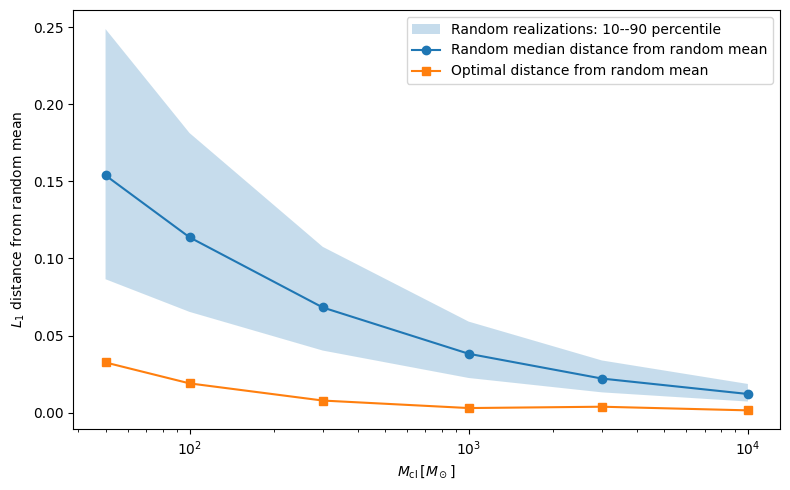

In [3]:
plt.figure(figsize=(8, 5))

plt.fill_between(
    df_center["M_cl"],
    df_center["random_p10"],
    df_center["random_p90"],
    alpha=0.25,
    label="Random realizations: 10--90 percentile"
)

plt.plot(
    df_center["M_cl"],
    df_center["random_median_distance"],
    marker="o",
    label="Random median distance from random mean"
)

plt.plot(
    df_center["M_cl"],
    df_center["d_opt_to_random_mean"],
    marker="s",
    label="Optimal distance from random mean"
)

plt.xscale("log")
plt.xlabel(r"$M_{\mathrm{cl}}\,[M_\odot]$")
plt.ylabel(r"$L_1$ distance from random mean")
plt.legend()
plt.tight_layout()
plt.show()


--- SUMMARY ---
    M_cl     d_opt  random_mean_distance  random_median_distance  random_p10  \
0     50  0.012695              0.080213                0.075042    0.040370   
1    100  0.007942              0.058571                0.054939    0.030073   
2    300  0.003261              0.034736                0.032781    0.018113   
3   1000  0.001346              0.019219                0.018175    0.010040   
4   3000  0.002086              0.011064                0.010531    0.005875   
5  10000  0.000804              0.006082                0.005771    0.003212   

   random_p90  
0    0.125256  
1    0.090662  
2    0.053901  
3    0.029710  
4    0.016991  
5    0.009353  


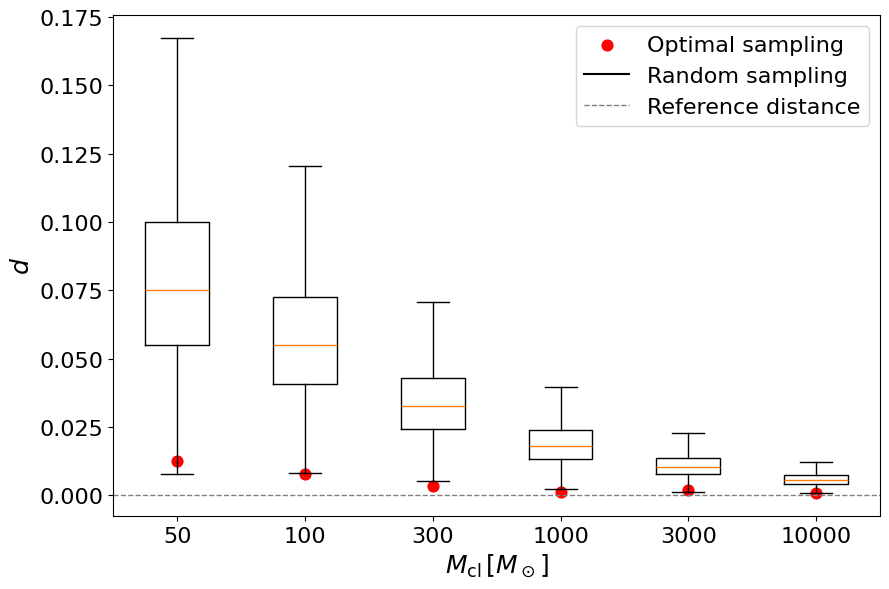

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random_df = pd.read_csv("../data/random_sampling_results.csv")
optimal_df = pd.read_csv("../data/optimal_sampling_clusters.csv")

masses = [50, 100, 300, 1000, 3000, 10000]

bin_cols_random = [f"bin_{i}_fraction" for i in range(1, 11)]
bin_cols_opt = [f"bin_{i}_number_fraction" for i in range(1, 11)]


def select_mass(df, mass_value, col="target_mass", tol=1e-8):
    return df[np.isclose(df[col], mass_value, atol=tol)]


boxplot_data = []
d_opt_list = []
labels = []
summary_rows = []

for M in masses:
    df_r = select_mass(random_df, M)
    df_o = select_mass(optimal_df, M)

    if df_r.empty or df_o.empty:
        print(f"Missing data for M = {M}")
        continue

    ref = df_r[bin_cols_random].mean().values.astype(float)

    random_vectors = df_r[bin_cols_random].values.astype(float)
    random_distances = np.linalg.norm(random_vectors - ref, axis=1)

    opt_vector = df_o.iloc[0][bin_cols_opt].values.astype(float)
    d_opt = np.linalg.norm(opt_vector - ref)

    boxplot_data.append(random_distances)
    d_opt_list.append(d_opt)
    labels.append(str(M))

    summary_rows.append({
        "M_cl": M,
        "d_opt": d_opt,
        "random_mean_distance": np.mean(random_distances),
        "random_median_distance": np.median(random_distances),
        "random_p10": np.percentile(random_distances, 10),
        "random_p90": np.percentile(random_distances, 90),
    })

summary = pd.DataFrame(summary_rows)

print("\n--- SUMMARY ---")
print(summary)

x_positions = np.arange(1, len(labels) + 1)

plt.figure(figsize=(9, 6))

plt.boxplot(
    boxplot_data,
    tick_labels=labels,
    showfliers=False
)

plt.scatter(
    x_positions,
    d_opt_list,
    color="red",
    marker="o",
    s=60,
    label="Optimal sampling"
)

plt.plot([], [], color="black", label="Random sampling")

plt.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1,
    label="Reference distance"
)

plt.xlabel(r"$M_{\mathrm{cl}}\,[M_\odot]$", fontsize=18)
plt.ylabel(r"$d$", fontsize=18)
plt.legend(fontsize=16)
plt.tick_params(axis="both", labelsize=16)
plt.tight_layout()
plt.show()